# 03 - Hypothesis: from EDA findings to testable claims, a model target and AI use cases

**Who worked on this notebook**

| Who | What |
| --- | --- |
| Peter Henskens | Asked for the notebook; chooses the hypothesis, the model target and the use cases (see the decision blocks) |
| Claude Code (AI assistant) | Read every cell and output of `02_eda.ipynb`, drafted the evidence summary, the candidate hypotheses, the tests, the model framing and the AI use cases; ran the notebook. Logged in `genai-log.md` |

**Goal.** `02_eda.ipynb` describes the data. This notebook turns that description into **claims we can test**,
tests the two that matter most, and decides what the model notebooks (`04` - `10`) will predict. It ends with
a list of AI use cases for this dataset.

**How it is built**
1. **What the EDA established** - every number in part 1 comes from an output of `02_eda.ipynb` (run of
   6 October 2026); the section of 02 is given next to it. Nothing in part 1 is recomputed on the server.
2. **Cross-check of two EDA results** - two results of 02 were first derived here from printed numbers,
   because their cells had not run; 02 has since been run top to bottom, and this part compares both.
3. **Candidate hypotheses** - six claims, what the EDA says about each, and which ones we test.
4. **Test 1 (H-A): is the e-bike share still rising?** - new queries on the server.
5. **Test 2 (H-D): does rain lower demand?** - new queries on the trips, the weather table and the holiday
   calendar in the project database.
6. **From hypothesis to model** - the target, a baseline to beat, and the evaluation design.
7. **AI use cases** for this project.
8. **Conclusions and what to carry forward.**

## 1. What the EDA established

Numbers use the project format (dot = thousands, comma = decimals). "02 §x" points to the section of
`02_eda.ipynb` where the output is shown.

### 1.1 The data
| # | Finding | Evidence (02) | Consequence here |
| --- | --- | --- | --- |
| D1 | 68 monthly files, Jan 2021 - Aug 2026, **no missing month**; 212.310.903 raw trips, 7,88 GB Parquet | §1.2 | Monthly series of 68 points is complete - usable for a trend test |
| D2 | The view drops **121.336 trips (0,057 %)**: 119.082 over 24 h, 1.760 negative duration, 494 under 1 min; the view holds exactly raw - removed = 212.189.567 | §2.1 | Cleaning does not change any conclusion; keep the view's rules |
| D3 | Missing values: end station 0,237 %, end coordinates 0,207 %, start station 0,040 %; `ride_id`, bike type, user type never empty; `ride_id` unique in July 2025 (4.986.246 trips) | §2.2, §2.3 | Station/distance analyses lose < 0,3 % of trips; city-level counts lose nothing |
| D4 | **2 days without any trip** (2021-02-02, 2026-02-23) and very low days: 2021-02-01 (238 trips, relative 0,01), 2026-01-25/26/27 (relative 0,07 - 0,21) | §3.4 | A daily model must handle gaps and extreme days; weather explains them or they are outages (tested in part 5) |
| D5 | Stations: 1.557 ids (2021) -> 2.438 (2026). Neither id nor name is a stable key: one id in two formats (`7386.10` / `7386.1`), 50 renumberings, 98 renames, 49 names with 99 spellings, system stations (`Lab - NYC`, `SYS032`). 2.921 keys -> 2.581 physical places at 50 m | §5.1, §5.3 | Any **station-level** target needs the station key of 02 §5.3 first; a **city-level** target does not |

### 1.2 Behaviour
| # | Finding | Evidence (02) | Consequence here |
| --- | --- | --- | --- |
| B1 | Strong **seasonality** and growth: trips per month mean 3.120.432, min 636.239, max 5.383.469; total trips 27,1 M (2021) -> 45,8 M (2025), **+68,8 %** | §3.1, §3.2 | Any comparison over time must remove season (pair by calendar month) and growth |
| B2 | Members ride at **commuter peaks** (08h, 17h - 18h weekdays), casual users in **weekend afternoons** | §3.3 | Weekday/weekend and hour are strong features; user type is a proxy for purpose |
| B3 | **E-bike share** 31,8 % (2021) -> 39,3 -> 50,2 -> 66,1 -> **70,5 % (2025)** -> 72,6 % (Jan - Aug 2026). Spearman rho = 0,949 over 68 months; first 12 months 34,0 %, last 12 months 72,1 % | §3.2 | The "going green" signal. 02 itself warns: rho is driven by 2021 - 2024 and the curve **flattens** from 2025 -> H-A |
| B4 | Classic trips **fell** 18,5 M -> 13,5 M (2021 -> 2025) while e-bike trips went 8,6 M -> 32,2 M | §3.2 | Something replaced classic trips, but most e-bike trips are new (B5) |
| B5 | Replace vs add (2021 -> 2025): classic trips lost 4.933.243, e-bike trips gained 23.496.480 -> **replacement explains at most 21,0 %** of the e-bike growth. Growth sits in short trips: 1 - 2 km +8,1 M, 0 - 1 km +5,9 M; only 21,4 % of the growth is in trips of 3 km or more | §4.6 | E-bikes mostly **add** trips, and not only long ones -> H-B |
| B6 | E-bike share rises with distance: 2025: 57,9 % (0 - 1 km) -> 71,8 % (1 - 2 km) -> 80,3 % (3 - 5 km) -> 88,1 % (8 km +) | §4.6 | Distance drives bike choice much more than user type (B8) |
| B7 | Network growth does **not** explain the e-bike shift: places in use since Jan 2021 (panel, 1.146 of 2.581) went 32,0 % -> 70,5 %, all other places 30,5 % -> 70,3 % | §5.4 | Shift-share in 2.1 below: almost all of the rise is *within* places -> H-C |
| B8 | Bike choice by user type (2025): casual 75,3 % e-bike, member 69,5 %. chi2 = 107.694, p ~ 0, **Cramer's V = 0,049 (negligible)** | §4.4 | User type is not a useful predictor of bike type -> H-F rejected |
| B9 | **Casual users ride longer**: median 12,7 vs 8,2 min; Mann-Whitney one-sided p ~ 0; rank-biserial r = 0,311 (medium) | §4.3 | Already tested; not a new hypothesis (H-E) |
| B10 | Median straight-line speed: member e-bike 12,54 km/h vs classic 9,27; casual e-bike 10,49 vs classic 7,36. No trip above 40 km/h. Round trips: casual 3,9 - 6,5 %, member 1,2 - 1,9 % | §4.5 | E-bikes are ~3 km/h faster (lower bound); round trips mark leisure use |
| B11 | **Rain lowers demand step by step**: median relative demand 1,03 (dry) -> 0,98 (0 - 2 mm) -> 0,88 (2 - 10 mm) -> 0,73 (10 - 25 mm) -> 0,66 (> 25 mm); Spearman rho = -0,448 over 2.067 days. Rain also raises the e-bike share (+2 pp above 10 mm, rho = 0,342), but that gap shrank from +7,9 pp (2022) to +1 - 2 pp (2024 - 2026). The two days without trips and the ten lowest days are snowstorms, heavy rain or holidays | §3.5 | Weather is the main day-to-day driver -> H-D. The 02 numbers include holidays, so the formal test leaves them out |
| B12 | **A weekday day off has about 17 % fewer trips** (relative demand 0,829) and a lower member share (79,7 % vs 83,5 %); the effect differs per holiday (Christmas Day 0,32, Thanksgiving 0,43 ... Election Day 1,20); the members' morning peak shrinks by a third | §3.6 | Holidays are a second calendar effect: left out of the rain test, grouped as a model feature |
| B13 | Casual users are a **shrinking minority**: 26,7 % of the trips in 2021, 17,4 % in 2025; the member peak rose from 2,2 M to 4,3 M per month, the casual peak stayed at 0,9 - 1,2 M | §3.1 | Daily demand is mostly commuting; the e-bike share of 02 §3.2 is mostly a member story |

## 2. Cross-check of two EDA results

When this notebook was first written (4 October 2026), two results of `02_eda.ipynb` had no usable output: the
sample check of §4.1 had never been executed, and the shift-share of §5.4 ended in a `NameError` because that cell
had been run before §4.6 defined `FROM_YEAR`. Both were derived here from numbers that 02 did print. On 6 October
2026 02 was corrected (the two years now live in its setup cell) and run top to bottom, so both results have their
own output. The derivations are kept as an **independent check** - they use nothing but typed-in numbers - and
the reading below compares them with what 02 now prints.

### 2.1 Sample check and shift-share, derived from 02 outputs
Both calculations below only use numbers printed in 02 (typed in, with their section), so they run without
the database.

**Sample check (02 §4.1).** For each share the 95 % margin of a random sample of size *n* is
1,96 · √(p · (1 - p) / n). A difference inside the margin is what chance alone produces.

**Shift-share (02 §5.4).** The change of the total e-bike share between two years is split exactly into
- *within* = Σ (average weight of a group) × (change of its share) - people at the same kind of place choosing
  e-bikes more often;
- *mix* = Σ (average share of a group) × (change of its weight) - the rise that comes only from new places
  getting more trips.

02 printed the shares rounded to 0,1 %, so the result is accurate to about 0,1 pp.

In [1]:
import numpy as np
import pandas as pd

# --- sample check: 02 §3.2 (2025 totals per bike type), §4.4 (2025 per user type), §4.1 (sample sizes)
pop_classic, pop_ebike = 13_514_461, 32_247_128                 # 02 §3.2, year 2025
pop_member = 11_541_115 + 26_237_102                            # 02 §4.4, member classic + e-bike
pop_total = pop_classic + pop_ebike
n, n_member = 178_652, 147_481                                  # 02 §4.1, sample rows and member count
n_ebike = 23_486 + 102_253                                      # 02 §4.5, casual + member e-bike trips in sample

check = pd.DataFrame({
    "population_%": [pop_member / pop_total * 100, pop_ebike / pop_total * 100],
    "sample_%": [n_member / n * 100, n_ebike / n * 100],
}, index=["member share", "e-bike share"])
check["difference_pp"] = check["sample_%"] - check["population_%"]
check["margin_95_pp"] = 1.96 * np.sqrt(check["population_%"] / 100 * (1 - check["population_%"] / 100) / n) * 100
check["within_margin"] = check.difference_pp.abs() <= check.margin_95_pp
print(f"sample = {n / pop_total * 100:.4f} % of 2025 trips (expected 1/256 = {100 / 256:.4f} %)")
display(check.round(3))

# --- shift-share 2021 -> 2025: 02 §5.4 per-group table (trips and e-bike share, panel / rest)
groups = pd.DataFrame({
    "trips_2021": [23_680_889, 3_423_486], "share_2021": [0.320, 0.305],
    "trips_2025": [32_426_946, 13_314_338], "share_2025": [0.705, 0.703],
}, index=["panel", "rest"])
w0 = groups.trips_2021 / groups.trips_2021.sum()
w1 = groups.trips_2025 / groups.trips_2025.sum()
s0, s1 = groups.share_2021, groups.share_2025
within = ((w0 + w1) / 2 * (s1 - s0)).sum() * 100
mix = ((s0 + s1) / 2 * (w1 - w0)).sum() * 100
pd.Series({"total_change_pp": within + mix, "within_pp": within, "mix_pp": mix,
           "mix_part_%": mix / (within + mix) * 100}).round(2).to_frame("shift-share 2021 -> 2025")

sample = 0.3904 % of 2025 trips (expected 1/256 = 0.3906 %)


,population_%,sample_%,difference_pp,margin_95_pp,within_margin
member share,82.554,82.552,-0.002,0.176,True
e-bike share,70.468,70.382,-0.086,0.212,True


,shift-share 2021 -> 2025
total_change_pp,38.63
within_pp,38.77
mix_pp,-0.14
mix_part_%,-0.36


**Reading the result**
- **The sample behaves like a random draw.** It is 0,3904 % of the 2025 trips (expected 1/256 = 0,3906 %). Member
  share 82,552 % in the sample vs 82,554 % in all of 2025 (difference -0,002 pp, margin ±0,176 pp); e-bike share
  70,382 % vs 70,468 % (-0,086 pp, margin ±0,212 pp). Both inside the margin. 02 §4.1 now prints the same check
  with the twelve months added: 13 of 14 shares inside the margin, March 0,15 pp over-represented against a margin
  of 0,12 pp - one miss in 14 is what chance produces.
- **Network growth explains none of the e-bike shift.** The total share rose 38,63 pp from 2021 to 2025; **within
  +38,77 pp, mix -0,14 pp**. The mix part is even slightly negative: new places got more weight but had a marginally
  *lower* share. The rise happened at the same kind of place, i.e. it is a change in how people ride. 02 §5.4 now
  prints the same split from the unrounded shares (within +38,78 pp, mix -0,15 pp), so the typed-in derivation was
  right to 0,01 pp. **H-C is answered**, and H-A can be read as a behavioural claim, not as a side effect of
  expansion.


## 3. Candidate hypotheses

Six claims that follow from the EDA. For each: what 02 already says, whether it can be tested with this data,
and what we do with it.

| | Claim (H1) | What 02 says | Testable? | Verdict |
| --- | --- | --- | --- | --- |
| **H-A** | The e-bike share is **still rising**: in the last 12 months it is higher than in the same months a year earlier | Strong rise 2021 - 2024 (rho 0,949), but 02 warns it flattens at ~70 - 72 % from 2025 | Yes - monthly aggregates, paired by calendar month | **Test in part 4** (going-green hypothesis) |
| **H-B** | Most e-bike trips are **new trips**, not former classic trips | Replacement explains at most 21,0 % of the e-bike growth, and the growth sits in short trips (B5) | Not formally: without a rider id we cannot follow a person between bike types, and total ridership grew 68,8 % in the same years, so "new" does not mean "caused by e-bikes"; only an upper bound | Reported as a bounded finding, not as the hypothesis |
| **H-C** | The e-bike shift is a change in **behaviour**, not an effect of new stations | Panel and rest rise almost identically (B7); mix part ~0 (2.1) | Answered by the shift-share | Answered - supports H-A as a behavioural claim |
| **H-D** | **Rain lowers demand**: on wet days fewer trips than on a dry day of the same month | 02 §3.5: median relative demand falls step by step from 1,03 (dry) to 0,66 (> 25 mm), rho = -0,448 - without a formal test and with the holidays included | Yes - daily counts + NOAA | **Test in part 5** (feeds the model) |
| **H-E** | Casual users ride longer than members | Tested: r = 0,311, medium (B9) | Done | Not repeated |
| **H-F** | User type determines the choice of bike | V = 0,049, negligible (B8) | Done | Rejected |

**Decision: which hypothesis is "the" Citi Bike hypothesis of the project.**
Options:
- **A** - H-A only. Fits the theme *going green* directly and is testable, but no prediction model follows from it.
- **D** - H-D only. Leads straight into the model (weather as a feature), but the link with the theme is weak.
- **A + D** - H-A as the theme hypothesis of the EDA, H-D as the hypothesis that justifies the model's features.

**Recommendation: A + D.** The course asks for a testable hypothesis in the EDA *and* a model pipeline. H-A answers
the theme question ("is the city still going greener?"); H-D explains *why* the model gets weather inputs and gives
the model notebooks something to prove (a model with weather beats a model without). The team decides.

## 4. Test 1 (H-A): is the e-bike share still rising?

### 4.0 Setup
Same connection and helpers as `02_eda.ipynb`, imported from `citibike/connection.py`: the login comes from the git-ignored `.env`, `sql()` prints how
long a query took, `fmt()` and the table display hook give the project number format, and the colours mean the
same as in 02 (member blue, casual orange, classic green, e-bike violet).

In [2]:
import sys

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats

sys.path.insert(0, "..")   # citibike/ -> connection.py (pg8000 driver, credentials from .env)
from connection import engine, sql, fmt, check_connection, notebook_style, COLORS, LABELS, thousands

check_connection()
notebook_style()

Connected as r0808910


### 4.1 The monthly e-bike share
The same aggregate as 02 §3.1 (trips per month, user type and bike type), so the numbers match 02.

The total is 185 trips below the view count of 02 §2.1, because the query starts at 1 January 2021 and 02 §3.1 noted a handful of trips that start on 31 December 2020.

In [3]:
monthly = sql('''
    SELECT date_trunc('month', started_at) AS month, member_casual, rideable_type, count(*) AS trips
    FROM citibike.trips WHERE started_at >= '2021-01-01' GROUP BY 1, 2, 3
''')
monthly["month"] = pd.to_datetime(monthly.month)

per_user = monthly.pivot_table(index=["month", "member_casual"], columns="rideable_type", values="trips", aggfunc="sum")
shares = (per_user.electric_bike / per_user.sum(axis=1) * 100).unstack()
totals = monthly.pivot_table(index="month", columns="rideable_type", values="trips", aggfunc="sum")
shares["all"] = totals.electric_bike / totals.sum(axis=1) * 100
shares = shares.asfreq("MS")

last = shares.index.max()
print(f"{len(shares)} months, {shares.index.min():%Y-%m} -> {last:%Y-%m}; months without data: {shares['all'].isna().sum()}")
print(f"total trips: {fmt(int(totals.values.sum()))} (02 §2.1: 212.189.567)")

272 rows in 44,2 s
68 months, 2021-01 -> 2026-08; months without data: 0
total trips: 212.189.382 (02 §2.1: 212.189.567)


### 4.2 Test design

**Hypotheses.**
- H0: in the last 12 months (September 2025 - August 2026) the e-bike share is **not higher** than in the same
  calendar month one year earlier.
- H1: it is higher.

**Why pair by calendar month.** The share may move with the season (02 §3.2 shows a wavy line; its big swings
of 2021 - 2023 more likely reflect how many e-bikes were on the street than the season, but a seasonal part cannot
be excluded). Comparing
September with September, October with October, ... removes the season from every difference. We get **12
differences**; if the share is still rising, most of them are positive.

**Why the Wilcoxon signed-rank test.** It tests whether paired differences are centred above 0. It ranks the
differences by size and compares the ranks of the positive and the negative ones, so one extreme month cannot
dominate, and it does not assume the differences are normally distributed - with only 12 differences that
assumption cannot be checked. A paired t-test would need it.

**Why not Spearman over all 68 months (as in 02 §3.2).** 02 itself notes that rho is dominated by the steep
rise of 2021 - 2024 and says nothing about the recent period.

**Effect size.** The **median difference in percentage points** (how much higher) and the **matched-pairs
rank-biserial correlation** r = (rank sum of positive differences - rank sum of negative ones) / total rank sum,
from -1 (all lower) to +1 (all higher). With 12 pairs the smallest possible one-sided p-value is 1 / 2^12 = 0,00024
(all 12 higher).

**Comparison window.** The same test on the 12 months before (September 2024 - August 2025 vs a year earlier)
shows how big a rise *was*, so we can judge whether the recent rise is still of the same size or flattening.
We also run it per user type.

**Limits.** The 12 months are not independent (a month resembles the next), so the p-value is somewhat
optimistic, as in 02. And the share depends on **supply** too: if Citi Bike adds or removes e-bikes, the share
moves without anyone changing their mind. The data has no fleet counts, so this test measures *use*, not
*preference*.

In [4]:
def yoy_test(series: pd.Series, end: pd.Timestamp) -> pd.Series:
    # Pair the 12 months ending at `end` with the same calendar months one year earlier.
    months = pd.date_range(end=end, periods=12, freq="MS")
    now = series.reindex(months).to_numpy()
    before = series.reindex(months - pd.DateOffset(years=1)).to_numpy()
    d = now - before
    res = stats.wilcoxon(d, alternative="greater")
    ranks = stats.rankdata(np.abs(d))
    r = (ranks[d > 0].sum() - ranks[d < 0].sum()) / ranks.sum()
    return pd.Series({
        "window": f"{months[0]:%Y-%m} - {months[-1]:%Y-%m}",
        "share_%": now.mean(), "share_year_before_%": before.mean(),
        "median_diff_pp": float(np.median(d)), "months_higher": int((d > 0).sum()),
        "W": float(res.statistic), "p_one_sided": float(res.pvalue), "rank_biserial": float(r),
    })

results = pd.DataFrame([
    yoy_test(shares[group], end).rename(f"{group}, {label}")
    for group in ["all", "member", "casual"]
    for label, end in [("recent", last), ("year before", last - pd.DateOffset(years=1))]
])
for col in ["share_%", "share_year_before_%", "median_diff_pp", "W", "p_one_sided", "rank_biserial"]:
    results[col] = results[col].astype(float)
results["months_higher"] = results["months_higher"].astype(int)
results.round({"share_%": 1, "share_year_before_%": 1, "median_diff_pp": 2, "W": 0, "p_one_sided": 5, "rank_biserial": 3})

,window,share_%,share_year_before_%,median_diff_pp,months_higher,W,p_one_sided,rank_biserial
"all, recent",2025-09 - 2026-08,"72,1","69,4","2,85",12,78,"0,00024","1,000"
"all, year before",2024-09 - 2025-08,"69,4","62,3","5,82",12,78,"0,00024","1,000"
"member, recent",2025-09 - 2026-08,"71,2","68,2","3,01",12,78,"0,00024","1,000"
"member, year before",2024-09 - 2025-08,"68,2","61,0","6,08",12,78,"0,00024","1,000"
"casual, recent",2025-09 - 2026-08,"78,0","75,6","2,73",11,77,"0,00049","0,974"
"casual, year before",2024-09 - 2025-08,"75,6","68,8","5,45",12,78,"0,00024","1,000"


The chart shows the year-on-year difference of every month: the share minus the share of the same month a year
earlier. A bar above 0 means that month was greener than a year before; shrinking bars mean a flattening rise.

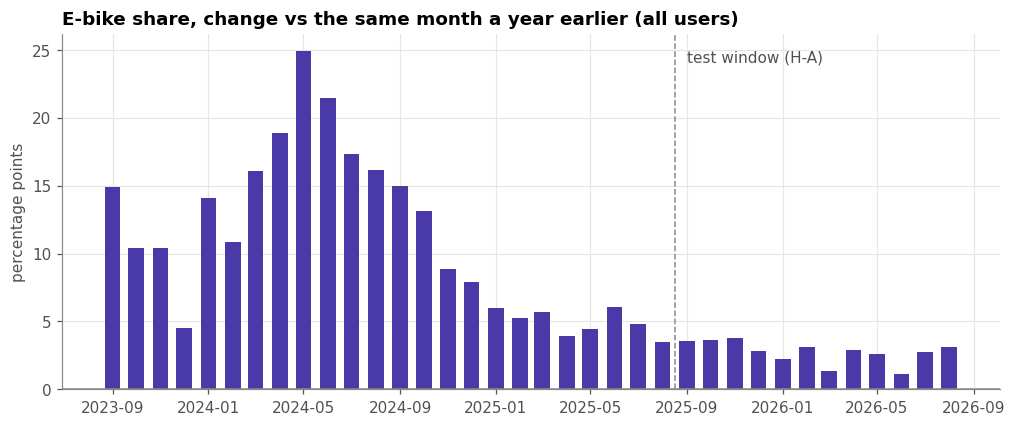

Year-on-year difference per month, last 24 months (pp):


,share_%,yoy_diff_pp
month,,
2024-09-01 00:00:00,"66,46","14,97"
2024-10-01 00:00:00,"66,90","13,16"
2024-11-01 00:00:00,"68,22","8,87"
2024-12-01 00:00:00,"69,81","7,91"
2025-01-01 00:00:00,"70,31","5,97"
2025-02-01 00:00:00,"69,76","5,26"
2025-03-01 00:00:00,"70,44","5,67"
2025-04-01 00:00:00,"69,43","3,89"
2025-05-01 00:00:00,"69,56","4,47"


In [5]:
diff = (shares["all"] - shares["all"].shift(12)).dropna()
recent = diff[diff.index > last - pd.DateOffset(years=3)]

fig, ax = plt.subplots()
ax.bar(recent.index, recent.values, width=20,
       color=[COLORS["electric_bike"] if v > 0 else "#c3c2be" for v in recent.values])
ax.axhline(0, color="#8a8986", linewidth=1)
ax.axvline(last - pd.DateOffset(months=11, days=15), color="#8a8986", linestyle="--", linewidth=1)
ax.annotate("test window (H-A)", (last - pd.DateOffset(months=11), ax.get_ylim()[1] * 0.92), color="#52514e")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.set_ylabel("percentage points")
ax.set_title("E-bike share, change vs the same month a year earlier (all users)")
plt.show()

print("Year-on-year difference per month, last 24 months (pp):")
pd.DataFrame({"share_%": shares["all"], "yoy_diff_pp": diff}).loc[last - pd.DateOffset(months=23):].round(2)

### 4.3 Reading the result
- **H0 is rejected: the e-bike share is still rising.** September 2025 - August 2026 averaged **72,1 %** against
  **69,4 %** in the same months a year earlier. **All 12 months** were higher, median **+2,85 pp**; Wilcoxon W = 78,
  one-sided **p = 0,00024** (the smallest value possible with 12 pairs) and rank-biserial **r = 1,00**: every
  difference points the same way.
- **The same holds per user group:** members +3,01 pp (12 of 12 months higher), casual users +2,73 pp (11 of 12,
  p = 0,00049, r = 0,97).
- **But the rise has halved.** In the year before, the median year-on-year rise was **+5,82 pp**. The monthly table
  and the chart show the slowdown: the year-on-year rise peaked around +25 pp in spring 2024 (chart), was +15,0 pp in September 2024, about +3 - 6 pp through 2025, and +1,1 - 3,1 pp in 2026 (lowest:
  June 2026 +1,11 pp, March 2026 +1,34 pp). The share is still climbing, but it is levelling off in the low 70s.
- **What this does not show.** It measures *use*, not *preference*: without fleet counts we cannot tell whether
  people want e-bikes more or Citi Bike simply put more e-bikes on the street. Price changes are not in the data
  either. As in 02, the p-value is somewhat optimistic because consecutive months are not independent; with 12 out
  of 12 months higher the conclusion does not depend on it.

**Hypothesis statement for the report:** *Between September 2025 and August 2026 the e-bike share of Citi Bike trips
was higher than in the same month a year earlier in every month (median +2,9 pp; Wilcoxon signed-rank, one-sided
p = 0,00024, r = 1,0). The rise is real, but half as large as the year before (+5,8 pp): the shift to e-bikes
continues while it slows down.*

## 5. Test 2 (H-D): does rain lower demand?

### 5.1 Daily trips with weather
The same daily aggregate as 02 §3.4 and the same weather as 02 §3.5: the table `citibike.weather_daily` (NOAA
station **New York Central Park**, `USW00094728`, loaded by the ingest backend). **Relative demand** is defined
as in 02: the trips of a day divided by the median of the same month and the same kind of day (weekday or
weekend), so season and growth drop out; 1,0 is a normal day.

**Holidays are left out of the test**, because a holiday lowers demand for a reason that has nothing to do with
the weather (02 §3.6: about 17 % fewer trips on a weekday day off). They come from the view
`citibike.calendar_day`: a day counts as a holiday when it has a public holiday (federal or New York State) on
its actual date **or** is the observed day off of one - so Christmas 2022 counts on Sunday 25 *and* Monday 26
December. Observances without a day off (Christmas Eve, Easter Sunday, ...) stay in the test.

In [6]:
daily = sql("""
    SELECT started_at::date AS day, rideable_type, count(*) AS trips
    FROM citibike.trips WHERE started_at >= '2021-01-01' GROUP BY 1, 2
""")
daily["day"] = pd.to_datetime(daily.day)

days = daily.pivot_table(index="day", columns="rideable_type", values="trips", aggfunc="sum", fill_value=0)
days["trips"] = days.classic_bike + days.electric_bike
days["ebike_share"] = days.electric_bike / days.trips * 100
days["weekend"] = days.index.dayofweek >= 5
days["relative"] = days.trips / days.groupby([days.index.to_period("M"), "weekend"]).trips.transform("median")

period = {"start": days.index.min().date(), "end": days.index.max().date()}
calendar_days = sql("""
    SELECT day, has_public_holiday, is_observed_day_off, public_holidays
    FROM citibike.calendar_day WHERE day BETWEEN :start AND :end
""", **period)
calendar_days["day"] = pd.to_datetime(calendar_days.day)
calendar_days = calendar_days.set_index("day")
days["holiday"] = (calendar_days.has_public_holiday | calendar_days.is_observed_day_off).reindex(days.index)

weather = sql("""
    SELECT day, tmax_c, tmin_c, prcp_mm, snow_mm, snow_depth_mm, wind_ms
    FROM citibike.weather_daily
    WHERE station = 'USW00094728' AND day BETWEEN :start AND :end
""", **period)
weather["day"] = pd.to_datetime(weather.day)
weather = weather.set_index("day").sort_index()
days = days.join(weather)
days["rain"] = pd.cut(days.prcp_mm, [-np.inf, 0, 2, 10, 25, np.inf],
                      labels=["dry", "0 - 2 mm", "2 - 10 mm", "10 - 25 mm", "> 25 mm"])   # right-closed, as in 02 §3.5

print(f"{fmt(len(days))} days with trips, {fmt(int(days.holiday.sum()))} holiday days "
      f"({fmt(int((days.holiday & days.weekend).sum()))} of them on a weekend), "
      f"{fmt(int(days.prcp_mm.isna().sum()))} days without precipitation data")

4.134 rows in 31,5 s


2.069 rows in 0,4 s


2.069 rows in 0,4 s
2.067 days with trips, 88 holiday days (13 of them on a weekend), 0 days without precipitation data


### 5.2 Test design

**Hypotheses.**
- H0: relative demand on **wet days** (more than 2 mm precipitation) is not lower than on **dry days** (0 mm).
- H1: it is lower.

Days with a trace of rain (0 - 2 mm, 2,0 mm included, the same class as in 02 §3.5) are left out of this comparison: it may have rained at night or for a few
minutes, so they belong to neither group. They stay in the Spearman correlation over all days.

**Test.** **Mann-Whitney U**, one-sided: relative demand is skewed (a storm day can be 0,1, a sunny day hardly
above 1,3), so we compare ranks, as in 02 §4.3. **Effect size:** rank-biserial r (negative = wet days lower) and
the median relative demand per group. **Dose-response:** Spearman rho between precipitation in mm and relative
demand over all non-holiday days - if rain matters, more rain should mean fewer trips.

**Limits.** One station for the whole city; precipitation is a day total, so rain at 3 am counts like rain at
rush hour; snow is included as its water equivalent. Days are not independent (a wet spell lasts several days).

dry days n = 1.287, median relative demand = 1,037
wet days n = 458, median relative demand = 0,819
trace days left out: 234, of which exactly 2,0 mm: 21
Mann-Whitney U = 104.916, one-sided p = 1,18e-93, rank-biserial r = -0,644
Spearman rho (precipitation vs relative demand, all non-holiday days) = -0,456, p = 2,07e-102, n = 1.979


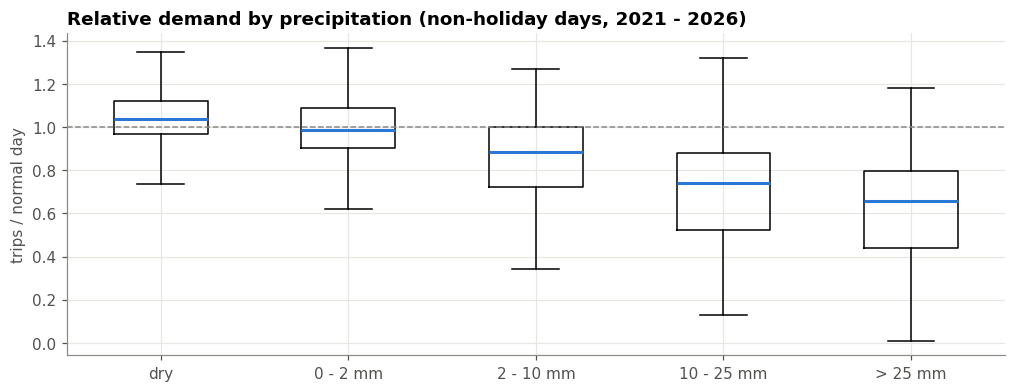

,days,median,q25,q75
rain,,,,
dry,1.287,"1,037","0,968","1,122"
0 - 2 mm,234,"0,985","0,902","1,091"
2 - 10 mm,244,"0,886","0,724","1,000"
10 - 25 mm,150,"0,741","0,524","0,880"
> 25 mm,64,"0,656","0,440","0,796"


In [7]:
test_days = days[~days.holiday & days.prcp_mm.notna()]
dry = test_days.loc[test_days.prcp_mm == 0, "relative"]
wet = test_days.loc[test_days.prcp_mm > 2, "relative"]   # > 2, not >= 2: exactly 2,0 mm is a trace day
trace = test_days.loc[(test_days.prcp_mm > 0) & (test_days.prcp_mm <= 2), "relative"]

u, p = stats.mannwhitneyu(wet, dry, alternative="less")
r_rb = 2 * u / (len(wet) * len(dry)) - 1
rho, p_rho = stats.spearmanr(test_days.prcp_mm, test_days.relative)

print(f"dry days n = {fmt(len(dry))}, median relative demand = {fmt(dry.median(), '.3f')}")
print(f"wet days n = {fmt(len(wet))}, median relative demand = {fmt(wet.median(), '.3f')}")
print(f"trace days left out: {fmt(len(trace))}, of which exactly 2,0 mm: {fmt(int((test_days.prcp_mm == 2).sum()))}")
print(f"Mann-Whitney U = {fmt(u, ',.0f')}, one-sided p = {fmt(p, '.2e')}, rank-biserial r = {fmt(r_rb, '.3f')}")
print(f"Spearman rho (precipitation vs relative demand, all non-holiday days) = {fmt(rho, '.3f')}, "
      f"p = {fmt(p_rho, '.2e')}, n = {fmt(len(test_days))}")

by_rain = test_days.groupby("rain", observed=True).relative.agg(days="size", median="median",
                                                               q25=lambda s: s.quantile(.25),
                                                               q75=lambda s: s.quantile(.75))
fig, ax = plt.subplots(figsize=(11, 3.8))
groups = [test_days.loc[test_days.rain == c, "relative"] for c in by_rain.index]
ax.boxplot(groups, labels=by_rain.index.astype(str), showfliers=False, widths=0.5,
           medianprops={"color": COLORS["member"], "linewidth": 2})
ax.axhline(1, color="#8a8986", linestyle="--", linewidth=1)
ax.set_ylabel("trips / normal day")
ax.set_title("Relative demand by precipitation (non-holiday days, 2021 - 2026)")
plt.show()
by_rain.round(3)

**Exploratory: does the weather change the choice of bike?** 02 §3.5 shows that rain raises the e-bike share;
here the check is repeated without the holiday days. As in 02, each day's e-bike share is compared with the median share of the 29 days around it, so the long-term rise drops
out. This is not a pre-stated hypothesis, only a check whether bike choice is a candidate second model target.

In [8]:
days["ebike_share_dev"] = days.ebike_share - days.ebike_share.rolling(29, center=True, min_periods=15).median()
explore = days[~days.holiday]
for var in ["tmax_c", "prcp_mm", "wind_ms"]:
    rho_v, p_v = stats.spearmanr(explore[var], explore.ebike_share_dev, nan_policy="omit")
    print(f"Spearman rho ({var} vs e-bike share deviation) = {fmt(rho_v, '.3f')}, p = {fmt(p_v, '.2e')}")
print("Median deviation of the e-bike share from the 29 days around it, per precipitation class (pp):")
display(explore.groupby("rain", observed=True).agg(days=("trips", "size"),
                                                   ebike_share_dev_pp=("ebike_share_dev", "median")).round(2))

print("Weather on the two days without any trip (02 §3.4):")
display(weather.loc[["2021-02-01", "2021-02-02", "2026-02-22", "2026-02-23"],
                    ["tmax_c", "prcp_mm", "snow_mm", "snow_depth_mm", "wind_ms"]])

print("The 10 days with the lowest relative demand, with their weather (02 §3.4 listed them without weather):")
days.nsmallest(10, "relative")[["trips", "relative", "holiday", "tmax_c", "prcp_mm", "snow_mm",
                                "snow_depth_mm", "wind_ms"]].round(2)

Spearman rho (tmax_c vs e-bike share deviation) = -0,091, p = 4,76e-05
Spearman rho (prcp_mm vs e-bike share deviation) = 0,341, p = 4,42e-55
Spearman rho (wind_ms vs e-bike share deviation) = 0,103, p = 5,52e-06
Median deviation of the e-bike share from the 29 days around it, per precipitation class (pp):


,days,ebike_share_dev_pp
rain,,
dry,1.287,"-0,27"
0 - 2 mm,234,"0,00"
2 - 10 mm,244,"0,95"
10 - 25 mm,150,"2,04"
> 25 mm,64,"2,13"


Weather on the two days without any trip (02 §3.4):


,tmax_c,prcp_mm,snow_mm,snow_depth_mm,wind_ms
day,,,,,
2021-02-01 00:00:00,"1,1","47,0",376,130,"6,4"
2021-02-02 00:00:00,"0,6","3,3",10,360,"3,8"
2026-02-22 00:00:00,"3,9","21,1",224,0,"5,1"
2026-02-23 00:00:00,"1,7","26,9",277,356,"4,4"


The 10 days with the lowest relative demand, with their weather (02 §3.4 listed them without weather):


,trips,relative,holiday,tmax_c,prcp_mm,snow_mm,snow_depth_mm,wind_ms
day,,,,,,,,
2021-02-01 00:00:00,238,"0,01",False,"1,1","47,0",376,130,"6,4"
2026-01-25 00:00:00,3.051,"0,07",False,"-5,6","45,7",290,25,"4,4"
2026-01-26 00:00:00,6.045,"0,08",False,"-2,8","0,5",0,229,"2,8"
2022-01-29 00:00:00,2.821,"0,13",False,"-1,6","19,6",185,150,"5,6"
2021-08-22 00:00:00,15.442,"0,15",False,"24,4","67,8",0,0,"2,3"
2021-05-30 00:00:00,17.283,"0,19",False,"10,6","22,6",0,0,"3,4"
2024-11-28 00:00:00,27.108,"0,20",True,"9,4","21,8",0,0,"2,5"
2025-12-27 00:00:00,12.864,"0,20",False,"-0,6","5,6",66,102,"2,9"
2022-12-25 00:00:00,9.118,"0,20",True,"-2,1","0,0",0,0,"3,8"


### 5.3 Reading the result
- **H0 is rejected: rain lowers demand, and strongly.** Wet days (more than 2 mm) have a median relative demand
  of **0,819** against **1,037** on dry days, about **21 % fewer trips** than a dry day of the same month.
  Mann-Whitney one-sided p = 1,2e-93; rank-biserial **r = -0,64, a large effect** (for comparison: the duration
  difference between casual users and members in 02 §4.3 was r = 0,31).
- **More rain, fewer trips (dose-response):** dry 1,037 -> 0 - 2 mm 0,985 -> 2 - 10 mm 0,886 -> 10 - 25 mm 0,741
  -> more than 25 mm 0,656. Spearman rho = -0,456 over 1.979 non-holiday days. The effect grows steadily with the
  amount, which is what a causal weather effect looks like (it is not a proof of one).
- **Rain also shifts the choice of bike** (exploratory): on wet days the e-bike share is above its local level,
  +0,95 pp at 2 - 10 mm, +2,04 pp at 10 - 25 mm, +2,13 pp above 25 mm, against -0,27 pp on dry days
  (rho = 0,34). Temperature (rho = -0,09) and wind (rho = 0,10) hardly matter. Either classic riders
  stay home more often in the rain, or riders take an e-bike to be out of the rain sooner; the data cannot
  separate the two. It is enough to make precipitation a feature for an e-bike-share target too.
- **The extreme days of 02 §3.4 are explained.** Both days *without any trip* fall in **heavy snowstorms**:
  1 - 2 February 2021 (376 mm snow, 360 mm snow on the ground) and 22 - 23 February 2026 (224 + 277 mm snow,
  356 mm on the ground). That fits a service suspension during a storm more than a gap in the files, although
  the data alone cannot prove which. Of the ten lowest days, six are snow days (2021-02-01, 2022-01-29,
  2025-12-27, 2026-01-25/26/27), two are heavy rain (2021-08-22 with 67,8 mm, 2021-05-30 with 22,6 mm at
  10,6 °C), and two are holidays: Thanksgiving with rain (2024-11-28) and Christmas Day 2022, dry. **No low day
  is left unexplained**, so 02 §3.4 found no data problem.
- **A correction to the earlier runs.** Until 5 October the test counted a day with exactly 2,0 mm as *wet*
  (`>= 2`) while the table showed it in the trace class (`0 - 2 mm`, a right-closed bin), so 21 days sat
  on both sides. Wet is now *more than* 2 mm, in line with the classes of 02 §3.5. The result changes in the
  third decimal (r -0,635 -> -0,644, rho -0,456 unchanged); the run history is in `genai-log.md`.


## 6. From hypothesis to model

### 6.1 What do we predict?
**Decision: the target of the model notebooks (05 - 10).**
- **A - daily trips for the whole city.** ~2.067 rows (one per day), inputs calendar + weather. Small enough for
  PyCaret and an AWS training job in minutes; a simple API (date + weather forecast -> expected trips); does not
  depend on the station key. Less operational value than per station.
- **B - departures per station per hour.** The question an operator really has (where will a dock run empty?), but
  ~2.400 stations × ~49.000 hours is ~120 M rows, it needs the station key of 02 §5.3 built first (04), and with the
  deadline of 15 October that is a risk.
- **C - member or casual, per trip.** Large tabular classification, easy for PyCaret, but the business question
  (who is a casual user?) is weak and the link with *going green* is missing.

**Recommendation (4 October): A**, with B as a stretch goal if time allows. A follows directly from H-D: if weather
moves demand, a model with weather inputs must beat a model that only knows the calendar - that is a claim the model
notebooks can prove or refute. A second output, the **daily e-bike share**, connects the model to the theme at no
extra data cost.

**Decision taken (team lead, 6 October 2026): trips per station per day, two horizons.** A variant between A and B:
the station is the unit (B's operational value), the day is the grain (A's size: about 5 M station-day rows instead
of ~120 M station-hours). Two targets per station: **trips tomorrow** and **trips from tomorrow to the end of the
month**. A second candidate, "where to build new stations next year", was dropped: the data measures demand only
where supply already exists, so such a model could only predict growth at the edge of the network, while a station
forecast is testable against what really happened and carries every step of the pipeline. One **global model over
all stations** (station as a feature, with lag and calendar features) is compared with per-station classical models
on a few busy stations; there is no model per station. What stays from this notebook: H-A and H-D as the hypotheses,
the weather as features for the day-ahead horizon, and the city-level baseline below as a reference.

### 6.2 A baseline to beat
A model is only useful if it beats a simple rule. Two *seasonal naive* rules that need no training:
- `lag_7`: tomorrow's same weekday last week - "next Tuesday is like last Tuesday";
- `mean_4_weeks`: the average of the same weekday in the last four weeks.

We score them on the **test period** we propose for the model notebooks: **1 January - 31 August 2026**
(the most recent data, never used for training). **MAE** (mean absolute error, in trips) is the main metric: it
is in the unit the operator thinks in and is not blown up by near-empty days. **MAPE** (mean absolute
percentage error) is shown for comparison, together with the median APE, because one outage day with a few
hundred trips can dominate a mean percentage.

Finally we check whether the errors of the baseline are related to the weather: if rain explains part of
what `lag_7` gets wrong, weather features have room to improve on it.

In [9]:
calendar = days.trips.asfreq("D")                # days without any trip become NaN, not 0
TEST_FROM = "2026-01-01"

base = pd.DataFrame({"actual": calendar})
base["lag_7"] = calendar.shift(7)
base["mean_4_weeks"] = pd.concat([calendar.shift(7 * k) for k in range(1, 5)], axis=1).mean(axis=1)
test = base.loc[TEST_FROM:].dropna()

scores = pd.DataFrame({
    rule: {"MAE_trips": (test.actual - test[rule]).abs().mean(),
           "MAPE_%": ((test.actual - test[rule]).abs() / test.actual).mean() * 100,
           "median_APE_%": ((test.actual - test[rule]).abs() / test.actual).median() * 100}
    for rule in ["lag_7", "mean_4_weeks"]
}).T
print(f"test period {test.index.min():%Y-%m-%d} -> {test.index.max():%Y-%m-%d}, {fmt(len(test))} days, "
      f"mean {fmt(test.actual.mean(), ',.0f')} trips per day")
display(scores.round(1))

# Is what lag_7 gets wrong related to the weather? log(actual / lag_7) > 0 means the day was busier than last week.
err = np.log(base.actual / base.lag_7).rename("log_error").to_frame().join(days[["prcp_mm", "tmax_c", "holiday"]])
err = err.dropna()
err = err[~err.holiday.astype(bool)]
err["prcp_change_mm"] = err.prcp_mm - days.prcp_mm.reindex(err.index - pd.Timedelta(days=7)).to_numpy()
err["tmax_change_c"] = err.tmax_c - days.tmax_c.reindex(err.index - pd.Timedelta(days=7)).to_numpy()
for var in ["prcp_change_mm", "tmax_change_c"]:
    rho_e, p_e = stats.spearmanr(err[var], err.log_error, nan_policy="omit")
    print(f"Spearman rho ({var} vs lag_7 error) = {fmt(rho_e, '.3f')}, p = {fmt(p_e, '.2e')}, n = {fmt(len(err))}")

test period 2026-01-01 -> 2026-08-31, 241 days, mean 124.859 trips per day


,MAE_trips,MAPE_%,median_APE_%
lag_7,29.799,"43,3","19,2"
mean_4_weeks,27.123,"42,1","18,9"


Spearman rho (prcp_change_mm vs lag_7 error) = -0,502, p = 3,61e-126, n = 1.971
Spearman rho (tmax_change_c vs lag_7 error) = 0,512, p = 5,93e-132, n = 1.971


**Holidays and the baseline.** `lag_7` copies the same weekday of last week, so a holiday hurts it twice: on the
holiday itself (last week was a normal day, so it predicts too many trips) and one week later (the reference day
is the holiday, so it predicts too few). The table compares the errors on those days with all other days, over
the whole period and in the test period. The *median error %* is the typical over- or under-prediction:
negative = `lag_7` predicted too many trips. A one-sided Mann-Whitney U test checks whether the relative absolute
error on holiday-related days is larger than on other days.

In [10]:
off = days.holiday.reindex(calendar.index, fill_value=False).astype(bool)
lag = pd.DataFrame({"actual": calendar, "lag_7": calendar.shift(7),
                    "holiday": off, "week_after_holiday": off.shift(7, fill_value=False)}).dropna()
lag["abs_error"] = (lag.actual - lag.lag_7).abs()
lag["relative_abs_error"] = lag.abs_error / lag.lag_7
lag["log_error"] = np.log(lag.actual / lag.lag_7)
lag["group"] = np.select([lag.holiday, lag.week_after_holiday], ["holiday", "a week after a holiday"], "other day")

whole = lag.groupby("group").agg(days=("actual", "size"), median_log_error=("log_error", "median"),
                                 median_abs_error=("abs_error", "median"), MAE=("abs_error", "mean"))
whole["median_error_%"] = (np.exp(whole.median_log_error) - 1) * 100
print("Whole period 2021 - 2026:")
display(whole.drop(columns="median_log_error").round(1))

in_test = lag.loc[TEST_FROM:]
test_groups = in_test.groupby("group").abs_error.agg(days="size", MAE="mean")
test_groups["share_of_total_error_%"] = in_test.groupby("group").abs_error.sum() / in_test.abs_error.sum() * 100
print(f"Test period {TEST_FROM} -> {in_test.index.max():%Y-%m-%d}:")
display(test_groups.round(1))

related = lag.group != "other day"
u_h, p_h = stats.mannwhitneyu(lag.loc[related, "relative_abs_error"], lag.loc[~related, "relative_abs_error"],
                              alternative="greater")
r_h = 2 * u_h / (related.sum() * (~related).sum()) - 1
print(f"Relative absolute error, holiday-related vs other days: Mann-Whitney one-sided p = {fmt(p_h, '.2e')}, "
      f"rank-biserial r = {fmt(r_h, '.3f')}, n = {fmt(int(related.sum()))} vs {fmt(int((~related).sum()))}")

Whole period 2021 - 2026:


,days,median_abs_error,MAE,median_error_%
group,,,,
a week after a holiday,77,17.553,"23.376,0","10,9"
holiday,87,16.909,"25.707,4","-7,5"
other day,1.894,14.045,"20.443,6","0,6"


Test period 2026-01-01 -> 2026-08-31:


,days,MAE,share_of_total_error_%
group,,,
a week after a holiday,8,"42.532,9","4,7"
holiday,9,"26.723,3","3,3"
other day,224,"29.467,6","91,9"


Relative absolute error, holiday-related vs other days: Mann-Whitney one-sided p = 3,16e-05, rank-biserial r = 0,188, n = 164 vs 1.894


### 6.3 Reading the result and the proposed model design
- **The bar to clear.** Over the 241 test days (Jan - Aug 2026 minus 23 February, which has no trips, and 2 March,
  whose `lag_7` falls on it; mean 124.859 trips per day) the better rule, `mean_4_weeks`, has an **MAE of 27.123
  trips** (`lag_7`: 29.799). A model in 05 - 09 is only useful if it gets **below 27.123 trips on this same test
  period**.
- **Why MAE and not MAPE.** MAPE is 42 - 43 %, the median APE only 19 %. The difference comes from a handful of
  storm days (25 - 27 January 2026 with 3 - 16 thousand trips), where a small error in trips is a huge error in
  percent. MAE is not distorted that way.
- **The weather is where the baseline goes wrong.** The `lag_7` error is strongly related to how the weather changed
  compared with a week earlier: rho = -0,502 for the change in precipitation (more rain than last week -> fewer trips
  than predicted) and rho = +0,512 for the change in maximum temperature. That is the room a model with weather
  inputs can use, and the direct link between H-D and the model.
- **Holidays are a second, smaller part of the error.** On a holiday `lag_7` predicts a median **7,5 % too many**
  trips, one week later **10,9 % too few** (its reference day was the holiday); on other days the median error is
  +0,6 %. Over the whole period the MAE on those days is 25.707 and 23.376 trips against 20.444 on other days;
  the relative error is larger (Mann-Whitney one-sided p = 3,2e-05), but the effect is **small (r = 0,19)**. In the
  test period the 17 holiday-related days carry **8,0 %** of the total error. A calendar feature that knows the
  holiday *and* the holiday of a week earlier is cheap and worth having, but the weather is the larger lever.
- **Fair comparison.** The baseline only uses trips from a week earlier; a model trained on *observed* weather of the
  day itself has information the API will only have as a forecast. 09 should mention this when it compares the
  model with the baseline.

**Proposed design for 04 - 09** (written 4 October for the city-level target; the rows that change with the
decision of 6 October are in the second table)

| Item | Proposal | Why |
| --- | --- | --- |
| Unit / target | one row per day, `trips` (all users); optional second target `ebike_share` | Follows from H-D and H-A; independent of the station key |
| Features - calendar | weekday, weekend flag, month, holiday (actual date or observed day off, from `citibike.calendar_day`), holiday a week earlier (for lag features), day number since 2021-01-01 (trend) | B1, B2: season, weekly rhythm and growth; 02 §3.6 and 6.3: holidays move demand and the `lag_7` error |
| Features - weather | `tmax_c`, `tmin_c`, `prcp_mm`, `snow_mm`, `snow_depth_mm`, `wind_ms` (NOAA Central Park, table `citibike.weather_daily`) | H-D; 23 days miss wind, 4 miss snow depth (02 §3.5 printout) - impute in 04 |
| Lag features | only if the forecast horizon allows them (a 1-day-ahead model may use yesterday; a 7-day-ahead model may not) | Avoids leakage: at prediction time only the past is known |
| Gaps | the 2 days without trips are left out (not set to 0); outage days decided in 04 | D4 |
| Split | train 2021 - 2024, validate 2025 (PyCaret / tuning), test Jan - Aug 2026 (once, at the end) | Time order: never train on the future |
| Metric | MAE in trips (main), MAPE and median APE (secondary), baseline from 6.2 as the bar to clear | MAE is interpretable and robust to near-empty days |
| Weather at prediction time | the API takes a weather **forecast** as input; the model is trained on observed weather | Honest about the gap between observed and forecast weather; to be mentioned in 09 |

**Changes after the decision of 6 October 2026 (station-day target)**

| Item | Decision | Why |
| --- | --- | --- |
| Unit / target | one row per **station and day** (`station_day`, built on the station key of 02 §5.3); target 1 `trips_tomorrow`, target 2 `trips_rest_of_month` (from tomorrow to the last day of the month) | The operator's question is per station; a direct target per horizon gives one measurable error each, no compounding of daily errors |
| Zeros vs gaps | 0 trips on a day the station was active; no row outside the station's lifetime (first to last trip) | A station that did not exist had no demand to measure; a row of zeros there would teach the model a false quiet |
| Model | **one global model** over all stations (PyCaret regression: gradient boosting, random forest, a linear baseline), station as a categorical feature; per-station ETS/ARIMA on a few busy stations as comparison only | Shared week and year seasons, calendar and weather are learned once; 2.400 separate models cannot be tuned, explained or retrained |
| Features | lags 1, 7, 14, 28; mean of the same weekday over the last 4 weeks; day type and holiday group; month and day of year; station age; the station's member and e-bike share over the previous 28 days; weather **only for the day-ahead target** | No lookahead: everything is known at prediction time; the weather of a day two weeks ahead is not |
| Baselines | tomorrow: same weekday last week; rest of month: month-to-date pace x remaining days, and the same remaining period a year earlier scaled by growth | A model that does not beat these adds nothing |
| Metric | RMSE and MAE per station-day, plus **WAPE** (sum of absolute errors / sum of actuals) | Stations differ by an order of magnitude in volume; MAPE explodes on small stations (see the city-level reading above) |
| Cold start | forecast only for stations with at least 28 days of history; report how many station-days that excludes | New stations have no lags; 2026 alone opened 159 places (02 §5.3) |
| Split | unchanged: train 2021 - 2024, validate 2025, test Jan - Aug 2026 | Time order, never train on the future |
| AWS / deploy | the feature table goes to S3; a SageMaker XGBoost training job trains the same model as locally; API: station + date in, both horizons and their baselines out; batch output per station shown on a map in the frontend | The push-to-retrain pipeline reads S3, not the database behind the VPN |


## 7. AI use cases for this project

The data supports more than one AI application. Each use case below says what is predicted or generated, which
data it uses, what it is worth (with the *going green* link), and how feasible it is before the final upload on
**15 October 2026**. Effort: S = days, M = a week, L = more than the time left.

| # | Use case | AI task | Target / output | Data | Value, green link | Effort | Fit with course pipeline |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | **Daily demand forecast** | Regression (tabular, time-ordered) | Trips per day for the city, optionally e-bike share | Daily counts + NOAA + calendar | Staffing, maintenance and rebalancing planning; forecasts e-bike demand (charging) | **S** | **Excellent** - small data, PyCaret, AWS, simple API |
| 2 | **Station demand and rebalancing** | Regression / count model per station-hour; net flow = arrivals - departures | Departures and arrivals per station per hour -> "empty / full in the next 2 h" | Trips + station key (02 §5.3) + weather | Fewer empty/full docks, fewer rebalancing van km = direct CO2 saving | L | Good, but needs the station key and ~120 M rows |
| 3 | **E-bike demand and charging** | Regression | E-bike trips per day / per area | As 1, split by bike type | Battery-swap and charging planning; follows the e-bike shift (H-A) | S (as 2nd output of 1) | Good - same pipeline as 1 |
| 4 | **Member or casual?** | Binary classification (tabular, large) | User type from start time, weekday, station, bike type, duration | Trip sample | Target casual users for membership (casual users ride for leisure, 02 §3.3) | S | Good for PyCaret, weak green link |
| 5 | **Trip duration at unlock** | Regression | Expected minutes of a trip | Start station, time, bike type, user type, weather | Expected return time -> better dock availability forecast | M | Fair - heavy-tailed target (02 §4.2) |
| 6 | **Anomaly and outage detection** | Unsupervised / forecast residuals | Flag days or stations whose demand is far below the forecast | Output of use case 1 + daily counts | Detects outages and data gaps (2021-02-02, 2026-02-23) and ingest errors in our own pipeline | S (on top of 1) | Good - reuses model 1 |
| 7 | **Station profiles** | Clustering (k-means on hourly profiles) | Station types: commuter, leisure, mixed | Station × hour-of-week counts | Explains where e-bikes and casual users concentrate; feature for 2 | S | Good - an unsupervised add-on for the EDA or 04 |
| 8 | **Station entity resolution** | Record linkage (rules + fuzzy name matching + time + location) | One stable station key from changing ids/names | Station keys of 02 §5.3 | Prerequisite for every station-level use case | M | Data prep (04), not a model notebook |
| 9 | **CO2 impact estimator** | Model output × assumptions (not ML on its own) | Estimated car-km and CO2 avoided per month | Trip distances (02 §4.6) + a substitution assumption from literature | Puts a number on *going green* | S | Presentation / frontend; the substitution factor is an **assumption**, not data, and must be shown as such |
| 10 | **Natural-language data assistant** | Generative AI (LLM text-to-SQL over the trips view, e.g. Anthropic Claude) | Answers questions like "e-bike share in Brooklyn last summer?" with the query shown | `citibike.trips` + a description of the columns | Makes the data usable without SQL | M | Extra on the frontend; needs a read-only login and query limits (the 10 min `statement_timeout`) |
| 11 | **Automatic monthly report** | Generative AI (LLM summary of computed aggregates) | A short monthly text: trips, e-bike share, unusual days, forecast vs actual | Aggregates + output of 1 and 6 | Shows the monthly ingest result in plain language | S | Extra; the LLM only words numbers that were computed, it computes none itself |

**Chosen (team lead, 6 October 2026): a station-day variant of use case 2**, without the rebalancing part: trips
per station for tomorrow and until the end of the month, one global model, as laid out in 6.1 and 6.3. Use case 1
becomes a reference (its city-level baseline in 6.2 stays useful), use case 2 at station-hour level and the
rebalancing stay out of scope, and the station key (use case 8) moves to the front of 04 because every row of the
new target depends on it.

**Recommendation as written on 4 October**
- **Main pipeline: use case 1** (with 3 as a second output). It follows from H-D, fits every step of the course
  (baseline, PyCaret, tuning, AWS, API, frontend, retraining on push) and is feasible before 15 October.
- **Cheap add-ons that reuse it:** 6 (anomaly flags from the forecast residuals) and 7 (station profiles) - each a
  few hours and both strengthen the story.
- **For the presentation:** 9, clearly labelled as an estimate under stated assumptions.
- **Out of scope for 15 October:** 2 (needs 8 first) - worth naming as the next step, because rebalancing is where
  the real CO2 saving of a bike-share operator lies.

For use cases 10 and 11: an LLM must not be the source of a number. It writes the SQL or the sentence; the
database computes the result, and the query is shown so a reader can check it.

## 8. Conclusions and what to carry forward
**Hypotheses**

| | Outcome | Evidence |
| --- | --- | --- |
| **H-A** e-bike share still rising | **Supported, but slowing** | 12 of 12 months higher than a year earlier, median +2,85 pp, p = 0,00024, r = 1,0; the rise halved from +5,82 pp (4.3) |
| **H-D** rain lowers demand | **Supported, large effect** | Wet (> 2 mm) vs dry median relative demand 0,819 vs 1,037, r = -0,64; steady dose-response, rho = -0,456 (5.3) |
| **H-B** most e-bike trips are new trips | Bounded, not tested | Replacement explains at most 21,0 % of the e-bike growth; the growth is in short trips; total ridership grew 68,8 % at the same time, so the data cannot say e-bikes *caused* it (02 §4.6) |
| **H-C** shift is behaviour, not expansion | Answered | Shift-share within +38,77 pp, mix -0,14 pp (2.1) |
| **H-E** casual users ride longer | Already shown in 02 | r = 0,311 (02 §4.3) |
| **H-F** user type drives bike choice | Rejected in 02 | Cramer's V = 0,049 (02 §4.4) |
| *exploratory* rain raises the e-bike share | Indication | +2 pp on days with more than 10 mm (5.3) |
| *exploratory* holidays explain part of the `lag_7` error | Small effect | holiday -7,5 %, a week later +10,9 % median error; r = 0,19; 8,0 % of the test-period error (6.3) |

**Decisions for the team** (Claude's recommendation in brackets)
1. The project hypothesis: H-A, H-D or both (**both**: H-A for the theme, H-D for the model) - part 3.
2. The model target: **decided on 6 October 2026: trips per station per day, two horizons (tomorrow, rest of the
   month), one global model** - 6.1 and the second table in 6.3. The daily city target stays as the reference
   baseline.
3. Split and metric: train 2021 - 2024, validate 2025, test Jan - Aug 2026; MAE, baseline 27.123 trips - 6.2/6.3.
4. Which AI use cases besides the main model (**6 anomaly flags and 7 station profiles**; 9 CO2 estimate for the
   presentation) - part 7.

**To carry forward**
- **02:** run top to bottom on 6 October 2026, 0 errors; §4.1 and §5.4 have their output and §6 Findings
  covers every section. Nothing is open.
- **04 data preparation:** three products. `station_dim`: the station key of 02 §5.3 (ids normalised to two
  decimals, consecutive ids on the same spot linked, hotspot as optional level, system stations and `JC`/`HB` ids
  dropped), with first and last trip. `station_day`: one row per station and active day with departures, arrivals,
  member and e-bike share; 0 on a quiet day, no row outside the station's lifetime. `daily_city`: one row per day with
  the calendar features from `citibike.calendar_day` (actual holiday date and observed day off, grouped by the size of
  the effect in 02 §3.6) and the weather from `citibike.weather_daily` (impute the 23 missing wind values and 4
  missing snow depths). Decide whether the two snowstorm days without trips are left out or set to 0 (a closed system
  really has 0 trips, but we cannot prove it was closed); keep 2026 as the untouched test set.
- **05 baseline model:** report the model against the seasonal-naive MAE of 6.2 on the same test period.

In [11]:
engine.dispose()